In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Carga y exploración inicial del dataset SECOP II Valle 2024

In [3]:
# Cargar el dataset de secop2_valle_2024.csv
# dtype=str para evitar problemas con los tipos de datos al leer el archivo CSV
df_secop = pd.read_csv("secop2_valle_2024.csv", dtype=str)

# Visualización de los primeros 5 registros
df_secop.head(5)

,id_del_proceso,referencia_del_proceso,entidad,nit_entidad,ciudad_entidad,ordenentidad,modalidad_de_contratacion,tipo_de_contrato,estado_resumen,precio_base,valor_total_adjudicacion,duracion,unidad_de_duracion,proveedores_invitados,respuestas_al_procedimiento,proveedores_unicos_con,fecha_de_publicacion_del
0,CO1.REQ.10000017,PN ESBOL CD 007 2026,ESCUELA DE POLICIA SIMON BOLIVAR,800141336,No Definido,Territorial,Contratación directa,Prestación de servicios,Presentación de oferta,47000000,0,10,Mes(es),0,0,0,2026-01-30T00:00:00.000
1,CO1.REQ.10000026,IND-26-SC-04-1745,"INSTITUTO DEL DEPORTE, LA EDUCACIÓN FÍSICA Y L...",805012896,Cali,Territorial,Contratación régimen especial,Decreto 092 de 2017,Presentación de oferta,151760000,0,150,día(s),0,0,0,2026-01-28T00:00:00.000
2,CO1.REQ.10000047,DGF-PS-2026-26814,ALCALDIA DISTRITAL DE BUENAVENTURA-VALLE,890399045,Buenaventura,Territorial,Contratación directa,Prestación de servicios,Presentación de oferta,37874130,0,6,Mes(es),0,0,0,2026-01-28T00:00:00.000
3,CO1.REQ.10000083,PM-004-2026,PERSONERIA EL CERRITO VALLE,800255799,El Cerrito,Territorial,Contratación directa,Prestación de servicios,Presentación de oferta,8000000,0,2,Mes(es),0,0,0,2026-01-28T00:00:00.000
4,CO1.REQ.10000084,RESO-03-2026,INSTITUCION EDUCATIVA SANTA MARTA**,891901408,El Águila,Territorial,Contratación régimen especial,Compraventa,Presentación de oferta,2331250,0,6,día(s),0,0,0,2026-01-28T00:00:00.000


In [4]:
# Visualización de los últimos 5 registros
df_secop.tail(5)

,id_del_proceso,referencia_del_proceso,entidad,nit_entidad,ciudad_entidad,ordenentidad,modalidad_de_contratacion,tipo_de_contrato,estado_resumen,precio_base,valor_total_adjudicacion,duracion,unidad_de_duracion,proveedores_invitados,respuestas_al_procedimiento,proveedores_unicos_con,fecha_de_publicacion_del
356016,CO1.REQ.9999855,4146.010.32.1.0886.2026,SANTIAGO DE CALI DISTRITO ESPECIAL - SECRETARI...,890399011,Cali,Territorial,Contratación directa,Prestación de servicios,Presentación de oferta,14204000,0,120,día(s),0,0,0,2026-01-28T00:00:00.000
356017,CO1.REQ.9999924,202672,MUNICIPIO DE ANSERMANUEVO,800100532,Ansermanuevo,Territorial,Contratación directa,Prestación de servicios,Presentación de oferta,17000000,0,92,día(s),0,0,0,2026-01-28T00:00:00.000
356018,CO1.REQ.9999952,CD-133-2026,MUNICIPIO DE LA UNION,891901109,La Unión,Territorial,Contratación directa,Prestación de servicios,Presentación de oferta,13930638,0,6,Mes(es),0,0,0,2026-01-28T00:00:00.000
356019,CO1.REQ.9999963,IEMRS-001-2026,INSTITUCION EDUCATIVA MARINO RENGIFO SALCEDO,815004606,Candelaria,Territorial,Contratación régimen especial,Prestación de servicios,Presentación de oferta,5000000,0,4,Mes(es),0,0,0,2026-01-28T00:00:00.000
356020,CO1.REQ.9999991,1000-18-11-098-2026,MUNICIPIO DE YUMBO VALLE,890399025,No Definido,Territorial,Contratación directa,Prestación de servicios,Presentación de oferta,12100000,0,150,día(s),0,0,0,2026-01-28T00:00:00.000


In [5]:
# Tipo de datos por columna
df_secop.dtypes

id_del_proceso                 str
referencia_del_proceso         str
entidad                        str
nit_entidad                    str
ciudad_entidad                 str
ordenentidad                   str
modalidad_de_contratacion      str
tipo_de_contrato               str
estado_resumen                 str
precio_base                    str
valor_total_adjudicacion       str
duracion                       str
unidad_de_duracion             str
proveedores_invitados          str
respuestas_al_procedimiento    str
proveedores_unicos_con         str
fecha_de_publicacion_del       str
dtype: object

## Eliminar columnas (Features) irrelevantes

In [6]:
# Ajuste de la lista según los nombres de columna específicos presentes en el archivo del SECOP II
columnas_a_eliminar = [
    'URLProceso',
    'Codigo Proveedor',
    'ID del Portafolio',
    'Codigo Principal de Categoria'
]

# Eliminación de columnas irrelevantes si existen en el dataframe
# Se usa solo 'columns' para evitar el error de pandas
# y 'errors="ignore"' para no fallar si la columna no está presente
if any(col in df_secop.columns for col in columnas_a_eliminar):
    df_secop = df_secop.drop(
        columns=[col for col in columnas_a_eliminar if col in df_secop.columns],
        errors='ignore'
    )

df_secop.head(5)

,id_del_proceso,referencia_del_proceso,entidad,nit_entidad,ciudad_entidad,ordenentidad,modalidad_de_contratacion,tipo_de_contrato,estado_resumen,precio_base,valor_total_adjudicacion,duracion,unidad_de_duracion,proveedores_invitados,respuestas_al_procedimiento,proveedores_unicos_con,fecha_de_publicacion_del
0,CO1.REQ.10000017,PN ESBOL CD 007 2026,ESCUELA DE POLICIA SIMON BOLIVAR,800141336,No Definido,Territorial,Contratación directa,Prestación de servicios,Presentación de oferta,47000000,0,10,Mes(es),0,0,0,2026-01-30T00:00:00.000
1,CO1.REQ.10000026,IND-26-SC-04-1745,"INSTITUTO DEL DEPORTE, LA EDUCACIÓN FÍSICA Y L...",805012896,Cali,Territorial,Contratación régimen especial,Decreto 092 de 2017,Presentación de oferta,151760000,0,150,día(s),0,0,0,2026-01-28T00:00:00.000
2,CO1.REQ.10000047,DGF-PS-2026-26814,ALCALDIA DISTRITAL DE BUENAVENTURA-VALLE,890399045,Buenaventura,Territorial,Contratación directa,Prestación de servicios,Presentación de oferta,37874130,0,6,Mes(es),0,0,0,2026-01-28T00:00:00.000
3,CO1.REQ.10000083,PM-004-2026,PERSONERIA EL CERRITO VALLE,800255799,El Cerrito,Territorial,Contratación directa,Prestación de servicios,Presentación de oferta,8000000,0,2,Mes(es),0,0,0,2026-01-28T00:00:00.000
4,CO1.REQ.10000084,RESO-03-2026,INSTITUCION EDUCATIVA SANTA MARTA**,891901408,El Águila,Territorial,Contratación régimen especial,Compraventa,Presentación de oferta,2331250,0,6,día(s),0,0,0,2026-01-28T00:00:00.000


## Renombrar las columnas (Features)

In [7]:
# Columnas a renombrar para mejorar la legibilidad y consistencia del dataset
renombrar_columnas = {
    # Claves del proceso
    "id_del_proceso": "id_proceso",
    "referencia_del_proceso": "referencia",
    
    # Entidad y ubicación
    "nit_entidad": "nit",
    "ciudad_entidad": "ciudad",
    "ordenentidad": "orden_entidad",
    
    # Estado y contratación
    "modalidad_de_contratacion": "modalidad",
    "estado_resumen": "estado",
    
    # Valores económicos
    "valor_total_adjudicacion": "valor_adjudicado",
    
    # Proveedores y métricas
    "respuestas_al_procedimiento": "respuestas",
    "proveedores_unicos_con": "proveedores_unicos",
    
    # Fechas
    "fecha_de_publicacion_del": "fecha_publicacion"
}

# Aplicar el renombrado (las columnas no incluidas mantienen su nombre actual)
df_secop = df_secop.rename(columns=renombrar_columnas)

df_secop.head(5)

,id_proceso,referencia,entidad,nit,ciudad,orden_entidad,modalidad,tipo_de_contrato,estado,precio_base,valor_adjudicado,duracion,unidad_de_duracion,proveedores_invitados,respuestas,proveedores_unicos,fecha_publicacion
0,CO1.REQ.10000017,PN ESBOL CD 007 2026,ESCUELA DE POLICIA SIMON BOLIVAR,800141336,No Definido,Territorial,Contratación directa,Prestación de servicios,Presentación de oferta,47000000,0,10,Mes(es),0,0,0,2026-01-30T00:00:00.000
1,CO1.REQ.10000026,IND-26-SC-04-1745,"INSTITUTO DEL DEPORTE, LA EDUCACIÓN FÍSICA Y L...",805012896,Cali,Territorial,Contratación régimen especial,Decreto 092 de 2017,Presentación de oferta,151760000,0,150,día(s),0,0,0,2026-01-28T00:00:00.000
2,CO1.REQ.10000047,DGF-PS-2026-26814,ALCALDIA DISTRITAL DE BUENAVENTURA-VALLE,890399045,Buenaventura,Territorial,Contratación directa,Prestación de servicios,Presentación de oferta,37874130,0,6,Mes(es),0,0,0,2026-01-28T00:00:00.000
3,CO1.REQ.10000083,PM-004-2026,PERSONERIA EL CERRITO VALLE,800255799,El Cerrito,Territorial,Contratación directa,Prestación de servicios,Presentación de oferta,8000000,0,2,Mes(es),0,0,0,2026-01-28T00:00:00.000
4,CO1.REQ.10000084,RESO-03-2026,INSTITUCION EDUCATIVA SANTA MARTA**,891901408,El Águila,Territorial,Contratación régimen especial,Compraventa,Presentación de oferta,2331250,0,6,día(s),0,0,0,2026-01-28T00:00:00.000


## Eliminar filas (samples) duplicadas

In [8]:
# Dimensiones iniciales del dataset
df_secop.shape

(356021, 17)

In [9]:
# Conteo de filas duplicadas
duplicate_rows_df = df_secop[df_secop.duplicated()]
print("number of duplicate rows: ", duplicate_rows_df.shape)

number of duplicate rows:  (8541, 17)


In [10]:
# Conteo de registros no nulos por columna antes de eliminar duplicados
df_secop.count()

id_proceso               356021
referencia               356021
entidad                  356021
nit                      356021
ciudad                   356021
orden_entidad            356021
modalidad                356021
tipo_de_contrato         356021
estado                   356021
precio_base              356021
valor_adjudicado         356021
duracion                 356021
unidad_de_duracion       356021
proveedores_invitados    356021
respuestas               356021
proveedores_unicos       356021
fecha_publicacion        356021
dtype: int64

In [11]:
# Eliminación de duplicados
df_secop = df_secop.drop_duplicates()
df_secop.head(5)

,id_proceso,referencia,entidad,nit,ciudad,orden_entidad,modalidad,tipo_de_contrato,estado,precio_base,valor_adjudicado,duracion,unidad_de_duracion,proveedores_invitados,respuestas,proveedores_unicos,fecha_publicacion
0,CO1.REQ.10000017,PN ESBOL CD 007 2026,ESCUELA DE POLICIA SIMON BOLIVAR,800141336,No Definido,Territorial,Contratación directa,Prestación de servicios,Presentación de oferta,47000000,0,10,Mes(es),0,0,0,2026-01-30T00:00:00.000
1,CO1.REQ.10000026,IND-26-SC-04-1745,"INSTITUTO DEL DEPORTE, LA EDUCACIÓN FÍSICA Y L...",805012896,Cali,Territorial,Contratación régimen especial,Decreto 092 de 2017,Presentación de oferta,151760000,0,150,día(s),0,0,0,2026-01-28T00:00:00.000
2,CO1.REQ.10000047,DGF-PS-2026-26814,ALCALDIA DISTRITAL DE BUENAVENTURA-VALLE,890399045,Buenaventura,Territorial,Contratación directa,Prestación de servicios,Presentación de oferta,37874130,0,6,Mes(es),0,0,0,2026-01-28T00:00:00.000
3,CO1.REQ.10000083,PM-004-2026,PERSONERIA EL CERRITO VALLE,800255799,El Cerrito,Territorial,Contratación directa,Prestación de servicios,Presentación de oferta,8000000,0,2,Mes(es),0,0,0,2026-01-28T00:00:00.000
4,CO1.REQ.10000084,RESO-03-2026,INSTITUCION EDUCATIVA SANTA MARTA**,891901408,El Águila,Territorial,Contratación régimen especial,Compraventa,Presentación de oferta,2331250,0,6,día(s),0,0,0,2026-01-28T00:00:00.000


In [12]:
# Conteo de registros después de eliminar duplicados
df_secop.count()

id_proceso               347480
referencia               347480
entidad                  347480
nit                      347480
ciudad                   347480
orden_entidad            347480
modalidad                347480
tipo_de_contrato         347480
estado                   347480
precio_base              347480
valor_adjudicado         347480
duracion                 347480
unidad_de_duracion       347480
proveedores_invitados    347480
respuestas               347480
proveedores_unicos       347480
fecha_publicacion        347480
dtype: int64

## Eliminar valores nulos o faltantes (missing or null values)

In [13]:
# Suma de valores nulos por columna
print(df_secop.isnull().sum())

id_proceso               0
referencia               0
entidad                  0
nit                      0
ciudad                   0
orden_entidad            0
modalidad                0
tipo_de_contrato         0
estado                   0
precio_base              0
valor_adjudicado         0
duracion                 0
unidad_de_duracion       0
proveedores_invitados    0
respuestas               0
proveedores_unicos       0
fecha_publicacion        0
dtype: int64


In [14]:
# Reemplazar cadenas vacías, espacios o textos nulos por NaN real
textos_nulos = ["", " ", "NaN", "nan", "No Definido", "No aplica", "N/A"]
df_secop = df_secop.replace(textos_nulos, np.nan)

# Verificación de la suma de nulos reales tras la transformación
print("Conteo de valores nulos reales:")
print(df_secop.isnull().sum())

Conteo de valores nulos reales:
id_proceso                   0
referencia                   0
entidad                      0
nit                          0
ciudad                   36544
orden_entidad                0
modalidad                    8
tipo_de_contrato             0
estado                     379
precio_base                  0
valor_adjudicado             0
duracion                     0
unidad_de_duracion           0
proveedores_invitados        0
respuestas                   0
proveedores_unicos           0
fecha_publicacion            0
dtype: int64


In [15]:
# Imputación de valores nulos en columnas categóricas
df_secop['ciudad'] = df_secop['ciudad'].fillna('Desconocido')
df_secop['estado'] = df_secop['estado'].fillna('No Especificado')
df_secop['modalidad'] = df_secop['modalidad'].fillna('No Especificado')

# Verificación de que no queden valores nulos
print("Nulos restantes tras la imputación:")
print(df_secop.isnull().sum())

Nulos restantes tras la imputación:
id_proceso               0
referencia               0
entidad                  0
nit                      0
ciudad                   0
orden_entidad            0
modalidad                0
tipo_de_contrato         0
estado                   0
precio_base              0
valor_adjudicado         0
duracion                 0
unidad_de_duracion       0
proveedores_invitados    0
respuestas               0
proveedores_unicos       0
fecha_publicacion        0
dtype: int64


## Conversión de Tipos de Datos (Casting)

In [16]:
# 1. Limpieza y conversión de variables numéricas
cols_numericas = [
    'precio_base', 
    'valor_adjudicado', 
    'duracion', 
    'proveedores_invitados', 
    'respuestas', 
    'proveedores_unicos'
]

for col in cols_numericas:
    if col in df_secop.columns:
        # Remueve posibles caracteres especiales de texto como comas o signos de pesos
        df_secop[col] = (
            df_secop[col]
            .astype(str)
            .str.replace('$', '', regex=False)
            .str.replace(',', '', regex=False)
            .str.strip()
        )
        # Convierte a numérico; asigna NaN si hay caracteres no parseables
        df_secop[col] = pd.to_numeric(df_secop[col], errors='coerce')

# 2. Conversión de columna de fechas
df_secop['fecha_publicacion'] = pd.to_datetime(df_secop['fecha_publicacion'], errors='coerce')

# 3. Conversión de variables categóricas y de texto
cols_categoricas = [
    'orden_entidad', 'modalidad', 'tipo_de_contrato', 
    'estado', 'unidad_de_duracion', 'ciudad'
]

for col in cols_categoricas:
    df_secop[col] = df_secop[col].astype('category')

# Verificación del esquema de tipos
df_secop.dtypes

id_proceso                          str
referencia                          str
entidad                             str
nit                                 str
ciudad                         category
orden_entidad                  category
modalidad                      category
tipo_de_contrato               category
estado                         category
precio_base                       int64
valor_adjudicado                  int64
duracion                          int64
unidad_de_duracion             category
proveedores_invitados             int64
respuestas                        int64
proveedores_unicos                int64
fecha_publicacion        datetime64[us]
dtype: object

## Análisis Estadístico y Detección de Inconsistencias

In [17]:
# Resumen estadístico de las columnas numéricas
df_secop.describe().T

,count,mean,min,25%,50%,75%,max,std
precio_base,347480.0,140039314.445675,-37000000.0,7737000.0,13950000.0,25000000.0,600000000000.0,3079101059.123294
valor_adjudicado,347480.0,36162139.972588,0.0,0.0,0.0,0.0,3202146000000.0,5550106395.252413
duracion,347480.0,781.314703,0.0,4.0,12.0,93.0,134660400.0,270146.65611
proveedores_invitados,347480.0,16.194685,0.0,0.0,0.0,0.0,14226.0,238.610361
respuestas,347480.0,0.174116,0.0,0.0,0.0,0.0,113.0,1.435509
proveedores_unicos,347480.0,0.166283,0.0,0.0,0.0,0.0,113.0,1.342123
fecha_publicacion,347480,2025-05-16 22:49:46.669736,2024-01-01 00:00:00,2024-10-11 00:00:00,2025-06-05 00:00:00,2026-01-10 00:00:00,2026-08-31 00:00:00,NaN


## 🔍 Diagnóstico Clave del Dataset

<div style="padding: 15px; border-left: 5px solid #ff4b4b; background-color: #fff5f5; border-radius: 4px; margin-bottom: 20px;">
    <strong>⚠️ Alerta de Calidad de Datos:</strong> Se identificaron anomalías críticas en la distribución, registros en cero y errores de digitación que requieren una etapa estricta de limpieza antes del modelado.
</div>

### 1. Sesgo Extremo por Outliers (`precio_base`)
* **Mediana (50%):** $13,950,000 COP
* **Media:** $140,039,314 COP
* **Máximo:** $600,000,000,000 COP (600 mil millones)
* **Impacto:** La diferencia abismal entre la media (~$140M) y la mediana (~$13.95M), sumada a un percentil 75 de $25M frente a un máximo de $600 mil millones, confirma una **asimetría extrema a la derecha** causada por atípicos.

### 2. Dominio Masivo de Ceros ($0$)
* **`valor_adjudicado`:** Al menos el **75% del dataset está en $0 COP** (Percentil 75 = 0.0), a pesar de que el valor máximo alcanza los $320,214,600,000 COP. Esto ocurre por la presencia de borradores, contrataciones no finalizadas o descartadas.
* **`respuestas`, `proveedores_invitados` y `proveedores_unicos`:** Presentan percentil 75 en 0.0, lo que indica que **más del 75% de los 347,480 registros no registran interacción** o no reportaron ofertas.

### 3. Inconsistencias y Errores de Digitación
* **Valores Negativos:** Se detectan valores atípicos mínimos en `precio_base` de hasta **-$37,000,000 COP**, lo cual no es válido para licitaciones públicas.
* **Duración Irreal:** La variable `duracion` presenta un valor máximo de **134,660,400 unidades** (frente a una mediana de solo 12 unidades y un percentil 75 de 93), evidenciando un claro error tipográfico al registrar la información del contrato.

## Eliminación de inconsistencias lógicas

In [18]:
# 1. Contratos con precio base igual a cero o negativo
precios_cero = df_secop[df_secop['precio_base'] <= 0]
print(f"Contratos con precio base <= 0: {len(precios_cero)}")

# 2. Contratos con duración igual a cero o negativa
duracion_invalida = df_secop[df_secop['duracion'] <= 0]
print(f"Contratos con duración <= 0: {len(duracion_invalida)}")

# 3. Adjudicaciones donde el valor contratado excede desproporcionadamente el precio base
adjudicacion_anomala = df_secop[df_secop['valor_adjudicado'] > (df_secop['precio_base'] * 5)]
print(f"Contratos con adjudicación > 5x el precio base: {len(adjudicacion_anomala)}")

Contratos con precio base <= 0: 4906
Contratos con duración <= 0: 21875
Contratos con adjudicación > 5x el precio base: 42


In [19]:
# 1. Eliminar precios base negativos o iguales a cero
df_secop = df_secop[df_secop['precio_base'] > 0]

# 2. Eliminar duraciones iguales a cero (un contrato debe tener al menos 1 día/mes de duración)
df_secop = df_secop[df_secop['duracion'] > 0]

# 3. Eliminar adjudicaciones que excedan más de 5 veces el precio base 
# (asumiendo que es un error de digitación en la plataforma)
df_secop = df_secop[df_secop['valor_adjudicado'] <= (df_secop['precio_base'] * 5)]

print(f"Dimensión del dataset tras limpiar inconsistencias lógicas: {df_secop.shape}")

Dimensión del dataset tras limpiar inconsistencias lógicas: (321467, 17)


## Tratamiento de Outliers (Precio Base)

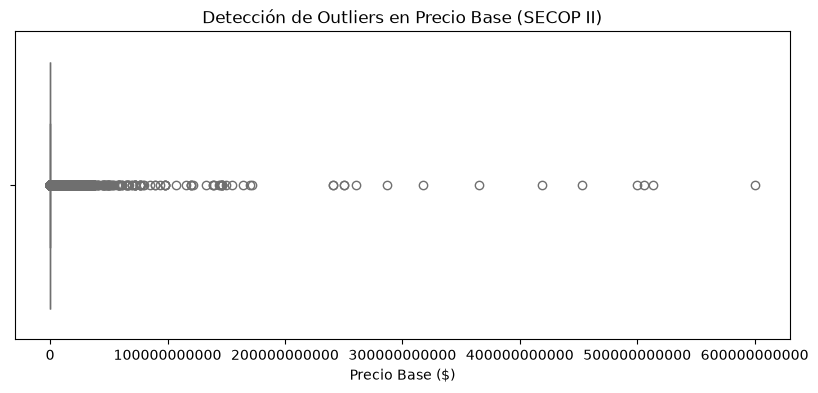

In [20]:
# Configuración del gráfico de caja para 'precio_base'
plt.figure(figsize=(10, 4))
sns.boxplot(x=df_secop['precio_base'], color='skyblue')
plt.title("Detección de Outliers en Precio Base (SECOP II)")
plt.xlabel("Precio Base ($)")
plt.ticklabel_format(style='plain', axis='x')
plt.show()

In [21]:
# Cálculo analítico de IQR para 'precio_base'
Q1 = df_secop['precio_base'].quantile(0.25)
Q3 = df_secop['precio_base'].quantile(0.75)
IQR = Q3 - Q1

limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

print(f"Cuartil 1 (Q1): {Q1:,.2f}")
print(f"Cuartil 3 (Q3): {Q3:,.2f}")
print(f"Rango Intercuartílico (IQR): {IQR:,.2f}")
print(f"Límite Superior para Outliers: {limite_superior:,.2f}")

# Conteo de registros por encima del límite superior
outliers_precio = df_secop[df_secop['precio_base'] > limite_superior]
print(f"Cantidad de observaciones atípicas (outliers): {len(outliers_precio)}")

Cuartil 1 (Q1): 8,000,000.00
Cuartil 3 (Q3): 24,974,400.00
Rango Intercuartílico (IQR): 16,974,400.00
Límite Superior para Outliers: 50,436,000.00
Cantidad de observaciones atípicas (outliers): 34383


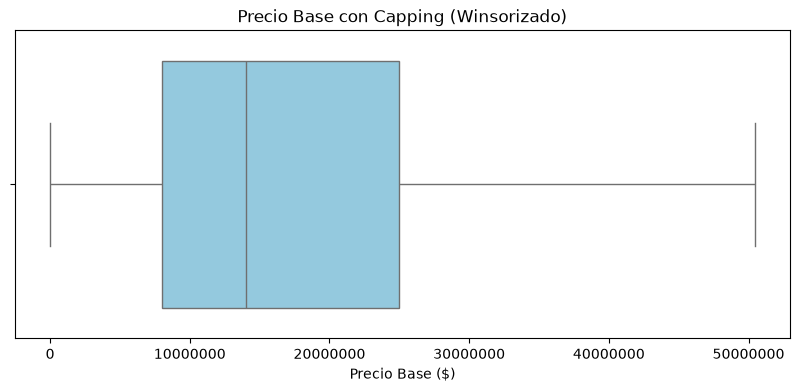

In [22]:
# 1. Cálculo de límites por IQR para 'precio_base'
Q1 = df_secop['precio_base'].quantile(0.25)
Q3 = df_secop['precio_base'].quantile(0.75)
IQR = Q3 - Q1

limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

# 2. Aplicar Capping con .clip()
# Los valores mayores al límite superior pasan a ser igual al límite superior
# Los valores menores al límite inferior pasan a ser igual al límite inferior
df_secop['precio_base_capped'] = df_secop['precio_base'].clip(
    lower=limite_inferior, 
    upper=limite_superior
)

# Verificación de la nueva distribución con boxplot
plt.figure(figsize=(10, 4))
sns.boxplot(x=df_secop['precio_base_capped'], color='skyblue')
plt.title("Precio Base con Capping (Winsorizado)")
plt.xlabel("Precio Base ($)")
plt.ticklabel_format(style='plain', axis='x')
plt.show()

## Tratamiento de Outliers (Duración)

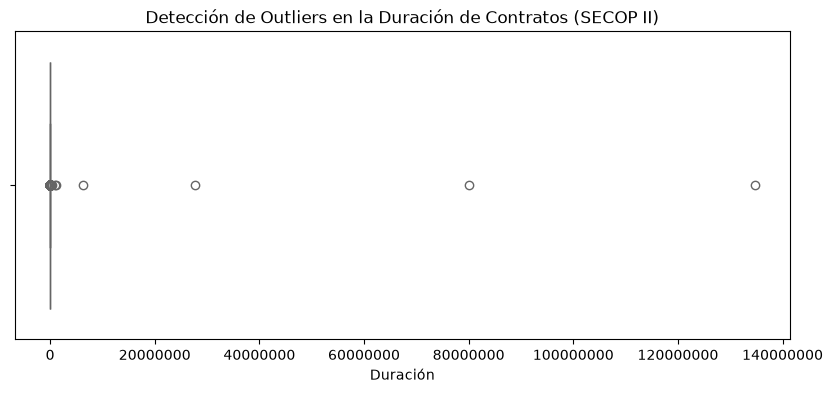

In [23]:
# Configuración del gráfico de caja para 'duracion'
plt.figure(figsize=(10, 4))
sns.boxplot(x=df_secop['duracion'], color='coral')
plt.title("Detección de Outliers en la Duración de Contratos (SECOP II)")
plt.xlabel("Duración")
plt.ticklabel_format(style='plain', axis='x')
plt.show()

In [24]:
# Cálculo analítico del Rango Intercuartílico (IQR) para 'duracion'
Q1_dur = df_secop['duracion'].quantile(0.25)
Q3_dur = df_secop['duracion'].quantile(0.75)
IQR_dur = Q3_dur - Q1_dur

limite_inferior_dur = Q1_dur - 1.5 * IQR_dur
limite_superior_dur = Q3_dur + 1.5 * IQR_dur

print(f"Cuartil 1 (Q1): {Q1_dur:,.2f}")
print(f"Cuartil 3 (Q3): {Q3_dur:,.2f}")
print(f"Rango Intercuartílico (IQR): {IQR_dur:,.2f}")
print(f"Límite Inferior para Outliers: {limite_inferior_dur:,.2f}")
print(f"Límite Superior para Outliers: {limite_superior_dur:,.2f}")

# Conteo de registros fuera de los límites
outliers_duracion = df_secop[(df_secop['duracion'] < limite_inferior_dur) | (df_secop['duracion'] > limite_superior_dur)]
print(f"Cantidad de observaciones atípicas (outliers) en 'duracion': {len(outliers_duracion)}")

Cuartil 1 (Q1): 4.00
Cuartil 3 (Q3): 100.00
Rango Intercuartílico (IQR): 96.00
Límite Inferior para Outliers: -140.00
Límite Superior para Outliers: 244.00
Cantidad de observaciones atípicas (outliers) en 'duracion': 15706


In [25]:
# Revisar las diferentes unidades de duración presentes
df_secop['unidad_de_duracion'].value_counts()

unidad_de_duracion
día(s)             184855
Mes(es)            135653
Semana(s)             452
Año(s)                394
Hora(s)               113
No Especificado         0
Name: count, dtype: int64

In [26]:
# Función para convertir todas las unidades a días
def convertir_a_dias(row):
    unidad = str(row['unidad_de_duracion']).strip().lower()
    valor = row['duracion']
    
    if 'mes' in unidad:
        return valor * 30
    elif 'año' in unidad:
        return valor * 365
    elif 'semana' in unidad:
        return valor * 7
    elif 'hora' in unidad:
        return valor / 24
    elif 'día' in unidad or 'dia' in unidad:
        return valor
    else:
        return np.nan

# Crear la nueva columna estandarizada
df_secop['duracion_dias'] = df_secop.apply(convertir_a_dias, axis=1)

# Verificación de la nueva variable
df_secop[['duracion', 'unidad_de_duracion', 'duracion_dias']].head(10)

,duracion,unidad_de_duracion,duracion_dias
0,10,Mes(es),300.0
1,150,día(s),150.0
2,6,Mes(es),180.0
3,2,Mes(es),60.0
4,6,día(s),6.0
5,20,Mes(es),600.0
6,118,día(s),118.0
7,181,día(s),181.0
8,185,día(s),185.0
9,151,día(s),151.0


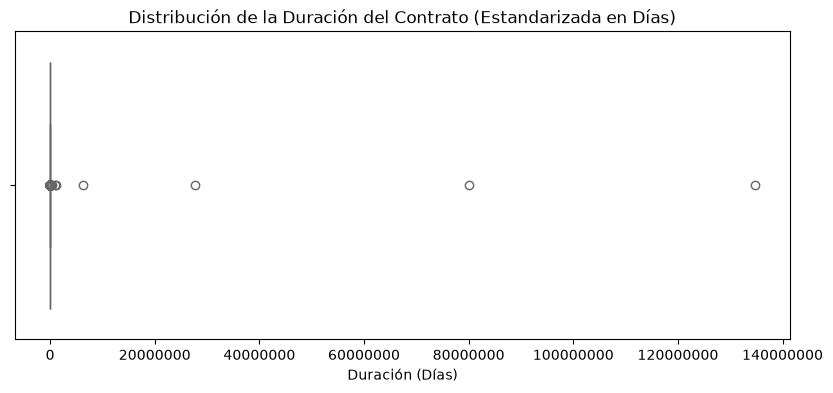

In [27]:
# Gráfica de caja (boxplot) de la duración estandarizada en días
plt.figure(figsize=(10, 4))
sns.boxplot(x=df_secop['duracion_dias'], color='coral')
plt.title("Distribución de la Duración del Contrato (Estandarizada en Días)")
plt.xlabel("Duración (Días)")
plt.ticklabel_format(style='plain', axis='x')
plt.show()

In [28]:
# Cálculo analítico de IQR para 'duracion_dias'
Q1_dur = df_secop['duracion_dias'].quantile(0.25)
Q3_dur = df_secop['duracion_dias'].quantile(0.75)
IQR_dur = Q3_dur - Q1_dur

limite_inferior_dur = Q1_dur - 1.5 * IQR_dur
limite_superior_dur = Q3_dur + 1.5 * IQR_dur

print(f"Cuartil 1 (Q1): {Q1_dur:,.2f} días")
print(f"Cuartil 3 (Q3): {Q3_dur:,.2f} días")
print(f"Rango Intercuartílico (IQR): {IQR_dur:,.2f} días")
print(f"Límite Superior para Outliers: {limite_superior_dur:,.2f} días")

# Conteo de registros que exceden el límite superior
outliers_dur = df_secop[df_secop['duracion_dias'] > limite_superior_dur]
print(f"Cantidad de observaciones atípicas en duración: {len(outliers_dur)}")

Cuartil 1 (Q1): 60.00 días
Cuartil 3 (Q3): 150.00 días
Rango Intercuartílico (IQR): 90.00 días
Límite Superior para Outliers: 285.00 días
Cantidad de observaciones atípicas en duración: 18698


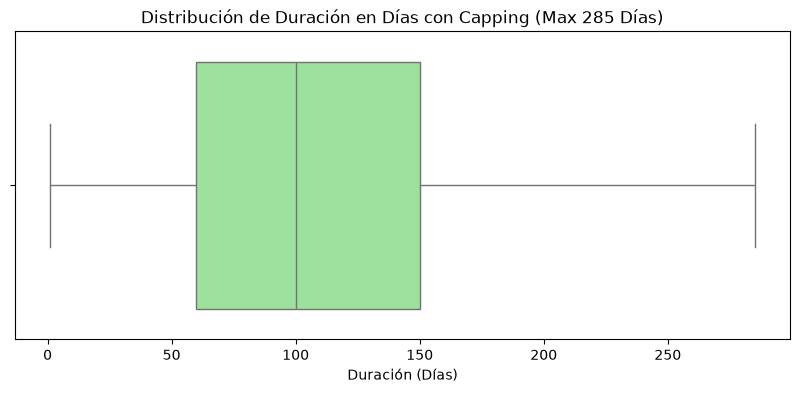

count    321467.000000
mean        111.332645
std          74.269962
min           1.000000
25%          60.000000
50%         100.000000
75%         150.000000
max         285.000000
Name: duracion_dias_capped, dtype: float64

In [29]:
# Aplicar Capping con el límite superior de 285 días
df_secop['duracion_dias_capped'] = df_secop['duracion_dias'].clip(
    lower=1, # Duración mínima lógica de 1 día
    upper=285.0
)

# Visualización del boxplot post-capping
plt.figure(figsize=(10, 4))
sns.boxplot(x=df_secop['duracion_dias_capped'], color='lightgreen')
plt.title("Distribución de Duración en Días con Capping (Max 285 Días)")
plt.xlabel("Duración (Días)")
plt.show()

# Verificación estadística del resultado
df_secop['duracion_dias_capped'].describe()

In [30]:
## Tratamiento de Outliers (Valor Adjudicado)

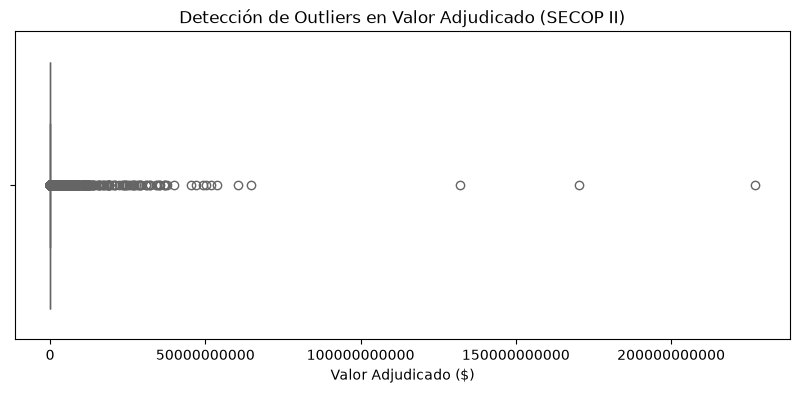

In [31]:
# Configuración del gráfico de caja para 'valor_adjudicado'
plt.figure(figsize=(10, 4))
sns.boxplot(x=df_secop['valor_adjudicado'], color='coral')
plt.title("Detección de Outliers en Valor Adjudicado (SECOP II)")
plt.xlabel("Valor Adjudicado ($)")
plt.ticklabel_format(style='plain', axis='x')
plt.show()

In [32]:
# Cálculo analítico del Rango Intercuartílico (IQR) para 'valor_adjudicado'
Q1_val = df_secop['valor_adjudicado'].quantile(0.25)
Q3_val = df_secop['valor_adjudicado'].quantile(0.75)
IQR_val = Q3_val - Q1_val

limite_inferior_val = Q1_val - 1.5 * IQR_val
limite_superior_val = Q3_val + 1.5 * IQR_val

print(f"Cuartil 1 (Q1): {Q1_val:,.2f}")
print(f"Cuartil 3 (Q3): {Q3_val:,.2f}")
print(f"Rango Intercuartílico (IQR): {IQR_val:,.2f}")
print(f"Límite Inferior para Outliers: {limite_inferior_val:,.2f}")
print(f"Límite Superior para Outliers: {limite_superior_val:,.2f}")

# Conteo de registros fuera de los límites
outliers_valor_adjudicado = df_secop[(df_secop['valor_adjudicado'] < limite_inferior_val) | (df_secop['valor_adjudicado'] > limite_superior_val)]
print(f"Cantidad de observaciones atípicas (outliers) en 'valor_adjudicado': {len(outliers_valor_adjudicado)}")

Cuartil 1 (Q1): 0.00
Cuartil 3 (Q3): 0.00
Rango Intercuartílico (IQR): 0.00
Límite Inferior para Outliers: 0.00
Límite Superior para Outliers: 0.00
Cantidad de observaciones atípicas (outliers) en 'valor_adjudicado': 12010


In [33]:
df_secop['estado'].value_counts(dropna=False)

estado
Presentación de oferta                         298111
Adjudicado                                      11623
Fase de ofertas                                  7123
Presentación de observaciones                    2605
Manifestación de interés (Menor Cuantía)         1274
No Especificado                                   363
Clarification submission                          199
Pré-Calificación de competidores                   88
Fase de Selección (Presentación de ofertas)        39
Selección de ofertas (borrador)                    36
Proceso de ofertas                                  6
Estimate Phase                                      0
Presentación de Observaciones                       0
Name: count, dtype: int64

In [34]:
# Detectar procesos terminados/adjudicados pero con valor 0
anomalias_cero = df_secop[(df_secop['estado'].isin(['Adjudicado'])) & (df_secop['valor_adjudicado'] == 0)]
print(f"Procesos finalizados con adjudicación en 0: {len(anomalias_cero)}")

Procesos finalizados con adjudicación en 0: 10


In [35]:
# Eliminar registros con estado 'Adjudicado' pero valor adjudicado igual a 0
df_secop = df_secop[~((df_secop['estado'] == 'Adjudicado') & (df_secop['valor_adjudicado'] == 0))]

print(f"Dimensión del dataset tras remover las 10 incoherencias: {df_secop.shape}")

Dimensión del dataset tras remover las 10 incoherencias: (321457, 20)


## Indicador binario de adjudicación

In [36]:
# Crear la variable binaria para diferenciar procesos con adjudicación efectiva de las ofertas abiertas
df_secop['es_adjudicado'] = (df_secop['valor_adjudicado'] > 0).astype(int)

# Verificación de distribución
print(df_secop['es_adjudicado'].value_counts(normalize=True) * 100)

es_adjudicado
0    96.263886
1     3.736114
Name: proportion, dtype: float64


## Análisis de Relación de Variables (Features)

### Heat Map

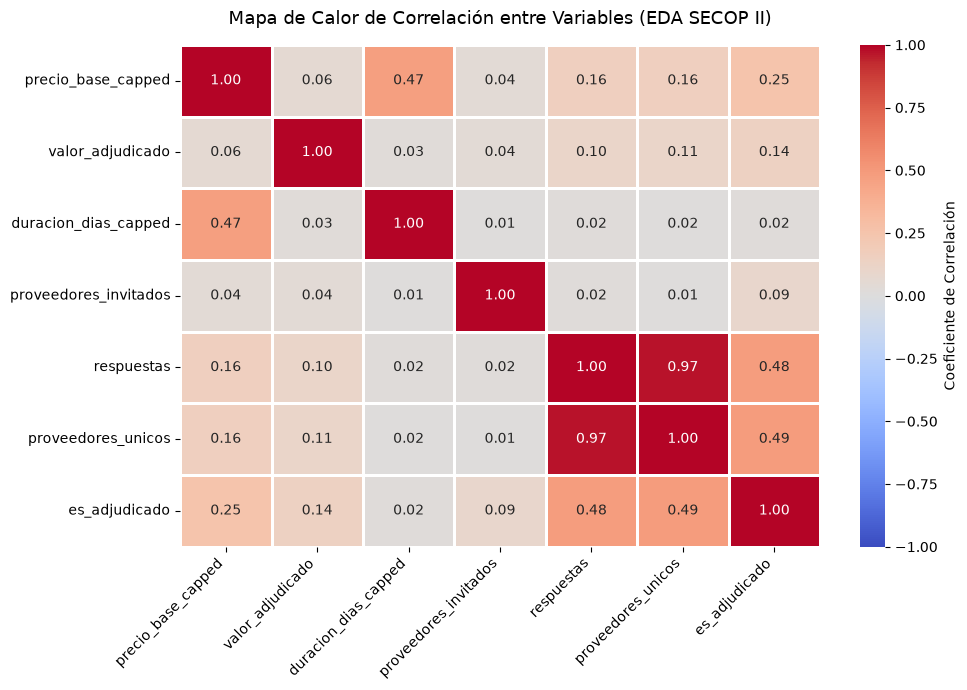

In [37]:
# 1. Selección de columnas numéricas clave (usando las versiones limpias/capped)
cols_corr = [
    'precio_base_capped',
    'valor_adjudicado',
    'duracion_dias_capped',
    'proveedores_invitados',
    'respuestas',
    'proveedores_unicos',
    'es_adjudicado'
]

# 2. Cálculo de la matriz de correlación de Pearson
matriz_corr = df_secop[cols_corr].corr()

# 3. Configuración del gráfico
plt.figure(figsize=(10, 7))
sns.heatmap(
    matriz_corr, 
    annot=True, 
    fmt=".2f", 
    cmap='coolwarm', 
    vmax=1, 
    vmin=-1, 
    linewidths=0.8,
    cbar_kws={'label': 'Coeficiente de Correlación'}
)

plt.title("Mapa de Calor de Correlación entre Variables (EDA SECOP II)", fontsize=13, pad=15)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

## 📊 Hallazgos Principales del Análisis de Correlación

### 1. Multicolinealidad Casi Perfecta: `respuestas` vs. `proveedores_unicos`
> **Correlación:** `0.97`

* **Diagnóstico:** Prácticamente cada respuesta recibida corresponde a un proveedor único diferente.
* **Recomendación:** Considerar eliminar una de las dos variables (por ejemplo, conservar solo `proveedores_unicos` o `respuestas`) para evitar introducir **ruido o sesgo por doble peso** en el modelo.

### 2. Relación entre Oferentes y Adjudicación
> **Correlación:** `0.48` / `0.49` (`respuestas` / `proveedores_unicos` vs. `es_adjudicado`)

* **Diagnóstico:** Es la correlación positiva más fuerte con el estado de adjudicación.
* **Conclusión:** Confirma que los procesos que registran participación real de oferentes tienen una **probabilidad significativamente mayor** de terminar en una adjudicación efectiva (en comparación con procesos en borrador o abandonados sin propuestas).

### 3. Presupuesto vs. Duración del Contrato
> **Correlación:** `0.47` (`precio_base_capped` vs. `duracion_dias_capped`)

* **Diagnóstico:** Correlación positiva moderada.
* **Conclusión:** Muestra una coherencia lógica de negocio: los contratos de mayor presupuesto tienden a contemplar **plazos de ejecución más largos**.

### 4. Impacto de Invitaciones Masivas
> **Correlación:** `0.01` – `0.09` (relacionadas con `proveedores_invitados`)

* **Diagnóstico:** El número de proveedores invitados formalmente **no garantiza** la recepción de respuestas (`0.02`) ni la adjudicación del contrato (`0.09`).
* **Conclusión:** En contratación pública, enviar invitaciones masivas no se traduce necesariamente en una participación efectiva.

### 5. Cuantía vs. Éxito de Adjudicación
> **Correlación:** `0.25` (`precio_base_capped` vs. `es_adjudicado`)

* **Diagnóstico:** Correlación positiva débil.
* **Conclusión:** Los contratos de mayor cuantía muestran una ligera tendencia superior a ser adjudicados frente a los de menor cuantía, los cuales suelen quedarse con mayor frecuencia en fases preliminares o de observación.

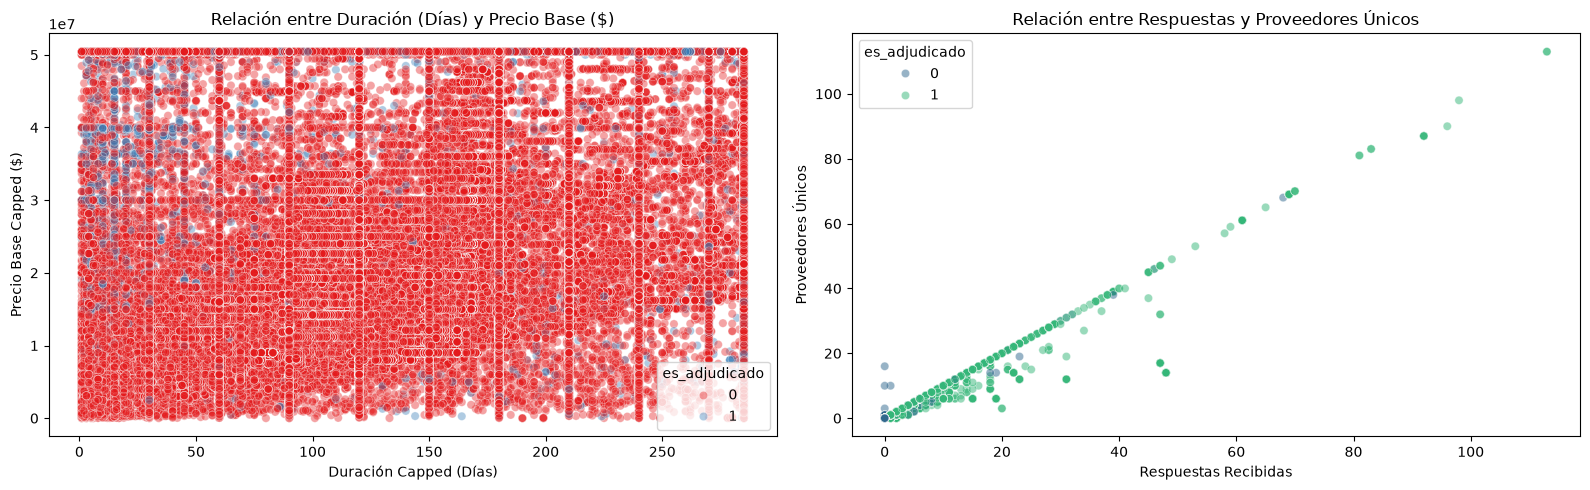

In [38]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# 1. Precio Base Capped vs. Duración Capped (Diferenciado por si se adjudicó)
sns.scatterplot(
    data=df_secop, 
    x='duracion_dias_capped', 
    y='precio_base_capped', 
    hue='es_adjudicado', 
    alpha=0.4, 
    palette='Set1', 
    ax=axes[0]
)
axes[0].set_title("Relación entre Duración (Días) y Precio Base ($)")
axes[0].set_xlabel("Duración Capped (Días)")
axes[0].set_ylabel("Precio Base Capped ($)")

# 2. Respuestas Recibidas vs. Proveedores Unicos
sns.scatterplot(
    data=df_secop, 
    x='respuestas', 
    y='proveedores_unicos', 
    hue='es_adjudicado', 
    alpha=0.5, 
    palette='viridis', 
    ax=axes[1]
)
axes[1].set_title("Relación entre Respuestas y Proveedores Únicos")
axes[1].set_xlabel("Respuestas Recibidas")
axes[1].set_ylabel("Proveedores Únicos")

plt.tight_layout()
plt.show()

## 📈 Análisis de los Gráficos de Dispersión

### 1. Relación entre Duración y Precio Base *(Gráfico Izquierdo)*

* **Patrón de Rejilla / Concentración Vertical:**
  Se aprecian **franjas verticales muy marcadas** en duraciones estandarizadas clave (por ejemplo: `30`, `60`, `90`, `120`, `150`, `180` y `285` días). Esto confirma que las entidades públicas estructuran los plazos contractuales en **bloques mensuales estandarizados** (1 mes, 2 meses, 6 meses, etc.).

* **Concentración de Ceros / No Adjudicados:**
  La masa principal de datos de contratos no adjudicados (`es_adjudicado == 0`) cubre prácticamente todo el plano. Esto reafirma la alta dispersión de las ofertas abiertas o inconclusas en comparación con la menor proporción de contratos que llegan a una adjudicación efectiva (puntos azules).

### 2. Relación entre Respuestas y Proveedores Únicos *(Gráfico Derecho)*

* **Alineación Diagonal ($y = x$):**
  > **Validación Visual:** La inmensa mayoría de los puntos se alinean perfectamente sobre la diagonal.

  Esto respalda de forma visual el coeficiente de **0.97** observado en la matriz de correlación: en casi todos los procesos, **cada propuesta recibida proviene de un oferente distinto**.

* **Patrón de Separación de Adjudicados:**
  Los contratos con un volumen de respuestas superior a **20 o 30** son de manera casi exclusiva exitosos (`es_adjudicado == 1`), evidenciando que **una alta participación prácticamente garantiza la adjudicación efectiva** del proceso.

/tmp/ipykernel_1475/2916124798.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(
/tmp/ipykernel_1475/2916124798.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
/tmp/ipykernel_1475/2916124798.py:41: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(
/tmp/ipykernel_1475/2916124798.py:59: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


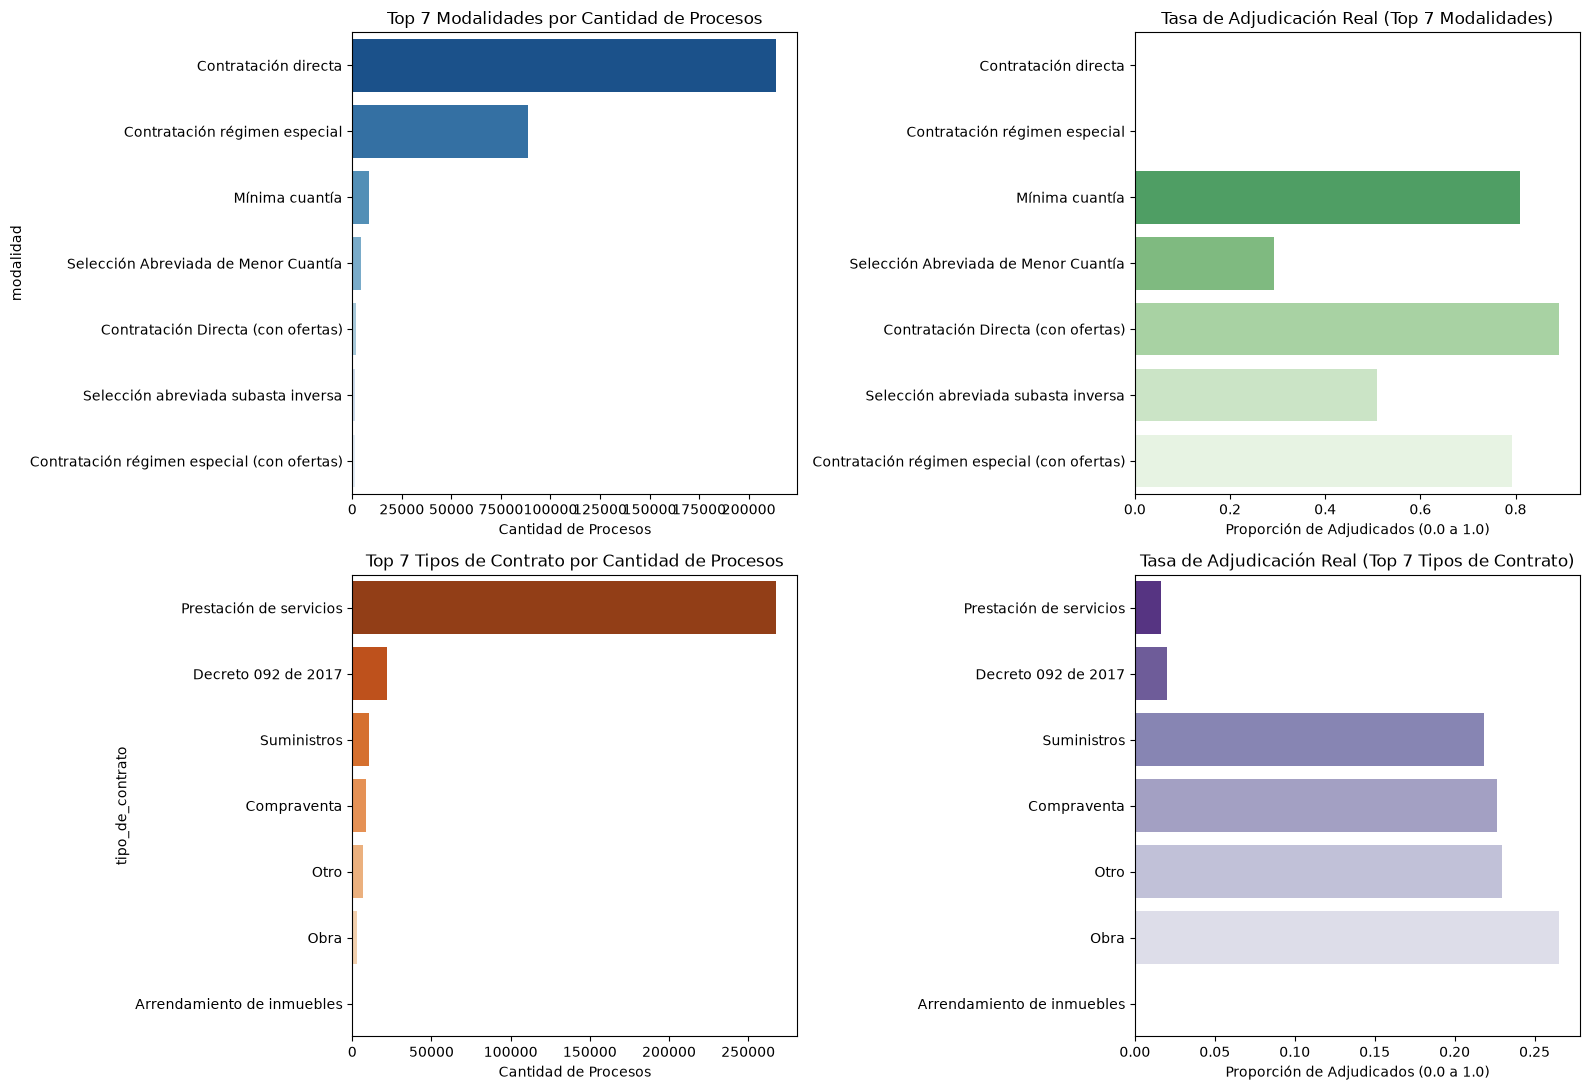

In [40]:
fig, axes = plt.subplots(2, 2, figsize=(16, 11))

# 1. Top 7 Modalidades - Volumen
top_modalidades = df_secop['modalidad'].value_counts().head(7).index
df_top_mod = df_secop[df_secop['modalidad'].isin(top_modalidades)]

sns.countplot(
    data=df_top_mod, 
    y='modalidad', 
    order=top_modalidades, 
    palette='Blues_r', 
    ax=axes[0, 0]
)
axes[0, 0].set_title("Top 7 Modalidades por Cantidad de Procesos", fontsize=12)
axes[0, 0].set_xlabel("Cantidad de Procesos")

# 2. Top 7 Modalidades - Tasa de Adjudicación Alineada
tasa_mod = (
    df_top_mod.groupby('modalidad')['es_adjudicado']
    .mean()
    .reindex(top_modalidades)
    .reset_index()
)

sns.barplot(
    data=tasa_mod, 
    y='modalidad', 
    x='es_adjudicado', 
    order=top_modalidades,
    palette='Greens_r', 
    ax=axes[0, 1]
)
axes[0, 1].set_title("Tasa de Adjudicación Real (Top 7 Modalidades)", fontsize=12)
axes[0, 1].set_xlabel("Proporción de Adjudicados (0.0 a 1.0)")
axes[0, 1].set_ylabel("")

# 3. Top 7 Tipos de Contrato - Volumen
top_tipos = df_secop['tipo_de_contrato'].value_counts().head(7).index
df_top_tipos = df_secop[df_secop['tipo_de_contrato'].isin(top_tipos)]

sns.countplot(
    data=df_top_tipos, 
    y='tipo_de_contrato', 
    order=top_tipos, 
    palette='Oranges_r', 
    ax=axes[1, 0]
)
axes[1, 0].set_title("Top 7 Tipos de Contrato por Cantidad de Procesos", fontsize=12)
axes[1, 0].set_xlabel("Cantidad de Procesos")

# 4. Top 7 Tipos de Contrato - Tasa de Adjudicación Alineada
tasa_tipo = (
    df_top_tipos.groupby('tipo_de_contrato')['es_adjudicado']
    .mean()
    .reindex(top_tipos)
    .reset_index()
)

sns.barplot(
    data=tasa_tipo, 
    y='tipo_de_contrato', 
    x='es_adjudicado', 
    order=top_tipos,
    palette='Purples_r', 
    ax=axes[1, 1]
)
axes[1, 1].set_title("Tasa de Adjudicación Real (Top 7 Tipos de Contrato)", fontsize=12)
axes[1, 1].set_xlabel("Proporción de Adjudicados (0.0 a 1.0)")
axes[1, 1].set_ylabel("")

plt.tight_layout()
plt.show()

## 🏷️ Análisis de los Resultados Categóricos

### 1. Modalidad de Contratación

* **Concentración del Volumen:**
  `Contratación directa` y `Contratación régimen especial` concentran **más del 90%** de los registros publicados en el dataset.

* **Efectividad de Adjudicación:**
  > **Alta Conversión:** Las modalidades con competencia pública o convocatorias de ofertas registradas (*Contratación Directa (con ofertas)*, *Mínima cuantía* y *Contratación régimen especial (con ofertas)*) registran la **tasa de adjudicación más alta**, situándose entre el **80% y el 90%**.

### 2. Tipo de Contrato

* **Frecuencia Operativa:**
  `Prestación de servicios` es, con amplia diferencia, el tipo contractual más frecuente en las publicaciones de la región (**>250,000 procesos**).

* **Desempeño de Adjudicación:**
  > **Sectores con Mayor Adjudicación:** Los contratos de `Obra`, `Otro`, `Compraventa` y `Suministros` presentan la mayor efectividad de adjudicación en SECOP II, con tasas que se ubican entre el **21% y el 27%**.

/tmp/ipykernel_1475/884008010.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(
/tmp/ipykernel_1475/884008010.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


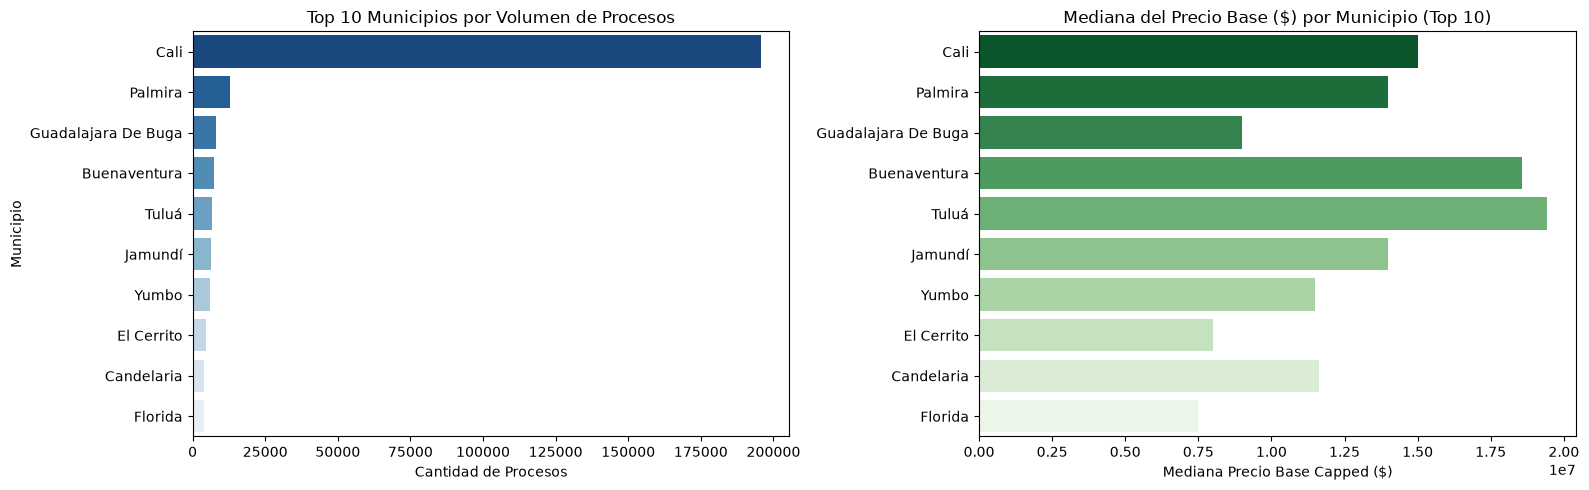

In [41]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Excluir valores nulos o categorías genéricas si aplica
top_ciudades = (
    df_secop[~df_secop['ciudad'].isin(['Desconocido', 'No Especificado'])]['ciudad']
    .value_counts()
    .head(10)
    .index
)
df_top_ciudades = df_secop[df_secop['ciudad'].isin(top_ciudades)]

# 1. Cantidad de procesos por municipio
sns.countplot(
    data=df_top_ciudades, 
    y='ciudad', 
    order=top_ciudades, 
    palette='Blues_r', 
    ax=axes[0]
)
axes[0].set_title("Top 10 Municipios por Volumen de Procesos", fontsize=12)
axes[0].set_xlabel("Cantidad de Procesos")
axes[0].set_ylabel("Municipio")

# 2. Mediana del Precio Base por municipio
mediana_precio_ciudad = (
    df_top_ciudades.groupby('ciudad')['precio_base_capped']
    .median()
    .reindex(top_ciudades)
    .reset_index()
)

sns.barplot(
    data=mediana_precio_ciudad, 
    y='ciudad', 
    x='precio_base_capped', 
    order=top_ciudades, 
    palette='Greens_r', 
    ax=axes[1]
)
axes[1].set_title("Mediana del Precio Base ($) por Municipio (Top 10)", fontsize=12)
axes[1].set_xlabel("Mediana Precio Base Capped ($)")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()

## 🗺️ Análisis Geográfico (Municipios del Valle del Cauca)

* **Concentración Absoluta en Cali:**
  La capital departamental domina ampliamente el volumen de contratación pública con **casi 200,000 procesos**, superando por un margen masivo a municipios como *Palmira*, *Buga* y *Buenaventura*.

* **Comportamiento del Presupuesto (Mediana del Precio Base):**
  * **Presupuestos más altos:** A pesar de que Cali lidera en volumen, **Tuluá** y **Buenaventura** presentan las medianas de presupuesto más elevadas (cercanas a los **$19M – $20M COP**).
  * **Presupuestos intermedios:** Cali y Palmira mantienen medianas estables alrededor de los **$14M – $15M COP**.
  * **Presupuestos menores:** Municipios como **El Cerrito** y **Florida** registran las medianas más bajas del departamento (cercanas a los **$7.5M – $8M COP**).

/tmp/ipykernel_1475/211648734.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(


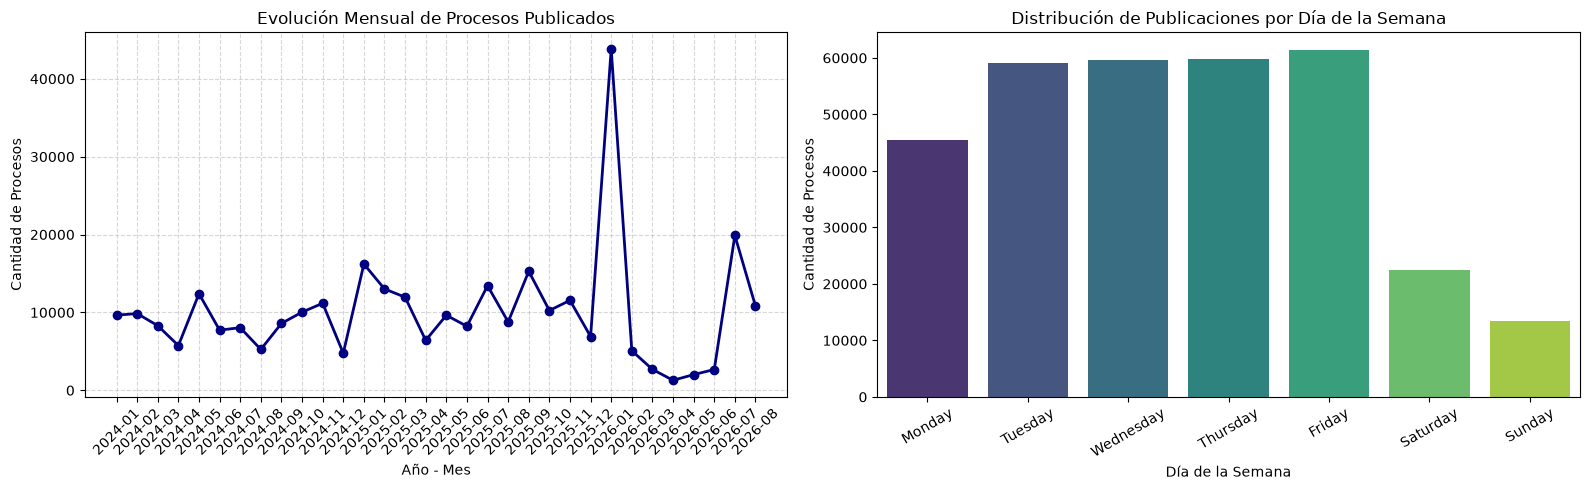

In [42]:
# Asegurar formato datetime en fecha_publicacion
df_secop['fecha_publicacion'] = pd.to_datetime(df_secop['fecha_publicacion'])

# Extraer componentes temporales
df_secop['año_mes'] = df_secop['fecha_publicacion'].dt.to_period('M').astype(str)
df_secop['mes_nombre'] = df_secop['fecha_publicacion'].dt.strftime('%b')
df_secop['dia_semana'] = df_secop['fecha_publicacion'].dt.day_name()

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# 1. Tendencia mensual de publicación de procesos
orden_meses = df_secop['año_mes'].sort_values().unique()
procesos_mes = df_secop.groupby('año_mes').size().reindex(orden_meses)

axes[0].plot(procesos_mes.index, procesos_mes.values, marker='o', color='navy', linewidth=2)
axes[0].set_title("Evolución Mensual de Procesos Publicados", fontsize=12)
axes[0].set_xlabel("Año - Mes")
axes[0].set_ylabel("Cantidad de Procesos")
axes[0].tick_params(axis='x', rotation=45)
axes[0].grid(True, linestyle='--', alpha=0.5)

# 2. Distribución por Día de la Semana
dias_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
sns.countplot(
    data=df_secop, 
    x='dia_semana', 
    order=dias_order, 
    palette='viridis', 
    ax=axes[1]
)
axes[1].set_title("Distribución de Publicaciones por Día de la Semana", fontsize=12)
axes[1].set_xlabel("Día de la Semana")
axes[1].set_ylabel("Cantidad de Procesos")
axes[1].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()

## 📅 Análisis Temporal (Evolución y Estacionalidad)

* **Pico Excepcional en Enero de 2026:**
  > **Comportamiento Histórico:** Entre 2024 y 2025 se observa una tendencia estable (promedio de 5,000 a 15,000 procesos mensuales), con incrementos leves al inicio de año (Ene/Feb) y al cierre de vigencia fiscal (Nov/Dic).
  >
  > **Anomalía / Estacionalidad 2026:** Destaca un **pico masivo atípico en Enero de 2026 (>43,000 procesos)**, impulsado por la carga masiva de contratos de prestación de servicios y contratación directa para el inicio del ciclo fiscal.

* **Distribución Semanal:**
  * **Días pico (Martes a Viernes):** La actividad de publicación se concentra fuertemente en este periodo, alcanzando aproximadamente **~60,000 procesos por día**.
  * **Inicio de semana (Lunes):** Muestra un volumen sensiblemente menor (**~45,000 procesos**).
  * **Fines de semana (Sábado y Domingo):** La actividad cae drásticamente, reflejando la dinámica operativa y administrativa estándar de las entidades públicas.